In [1]:
import pandas as pd
import numpy as np

In [2]:
logs = pd.read_csv("ALL_logs_kurssidata.csv")
print(logs.columns)
print(logs.head(6))
print(logs.dtypes)

Index(['Aika', 'Tapahtuman konteksti', 'Komponentti', 'Tapahtuman nimi',
       'Kuvaus', 'Alkuperä', 'Unnamed: 6', 'Unnamed: 7'],
      dtype='object')
         Aika Tapahtuman konteksti                           Komponentti  \
0   3.02.2026             11.48.49      Kurssi: Esi- ja alkuopetus kl-25   
1   3.02.2026             11.47.44      Kurssi: Esi- ja alkuopetus kl-25   
2   3.02.2026             00.48.00         Tentti: Tentti 2.5.-16.5.2025   
3   3.02.2026             00.47.46  Tentti: Uusintatentti 6.6.-13.6.2025   
4   3.02.2026             00.39.38      Kurssi: Esi- ja alkuopetus kl-25   
5  30.01.2026             18.27.07      Kurssi: Esi- ja alkuopetus kl-25   

  Tapahtuman nimi                 Kuvaus  \
0      Lokitiedot  Lokiraportti katsottu   
1     Järjestelmä           Kurssi nähty   
2          Tentti  Kurssin moduuli nähty   
3          Tentti  Kurssin moduuli nähty   
4     Järjestelmä           Kurssi nähty   
5      Lokitiedot  Lokiraportti katsottu   

     

Poistettavat idt:

179434, 
179631,
44240,
14552,
14294,
4688,
54402,
39644,
87979,
15115,
31281,
173796,
44240,
2067,
204691,
48118,
Id '-1’ 

In [3]:
print(logs["Unnamed: 7"].unique())

[nan 'web' 'ws' ' katsoi arvosanajakaumaa.']


In [4]:
l = ["179434", "179631", "44240", "14552", "14294", "4688", "54402", "39644", "87979", "15115", "31281", "173796",
      "44240", "2067", "204691", "48118", "-1" ]
logs1 = logs.copy()

print(logs1.shape)
print(logs1.shape)
for i in l:
    colname = "Incl "+i
    colname2 = "Incl2 "+i
    logs1[colname] = logs1["Alkuperä"].str.contains(i)
    logs1[colname2] = logs1["Unnamed: 6"].str.contains(i)
    logs1 = logs1[logs1[colname] == False]
    logs1 = logs1[logs1[colname2] == False]
    print(logs1[colname].unique())
    print(logs1[colname2].unique())
    print(logs1.shape)
    logs1 = logs1.drop([colname, colname2], axis=1)
    print(logs1.shape)
    print("----")
del colname, colname2

(86381, 8)
(86381, 8)
[False]
[False]
(84842, 10)
(84842, 8)
----
[False]
[False]
(84838, 10)
(84838, 8)
----
[False]
[False]
(83456, 10)
(83456, 8)
----
[False]
[False]
(82527, 10)
(82527, 8)
----
[False]
[False]
(82251, 10)
(82251, 8)
----
[False]
[False]
(82179, 10)
(82179, 8)
----
[False]
[False]
(82167, 10)
(82167, 8)
----
[False]
[False]
(82116, 10)
(82116, 8)
----
[False]
[False]
(82113, 10)
(82113, 8)
----
[False]
[False]
(81139, 10)
(81139, 8)
----
[False]
[False]
(81075, 10)
(81075, 8)
----
[False]
[False]
(80603, 10)
(80603, 8)
----
[False]
[False]
(80603, 10)
(80603, 8)
----
[False]
[False]
(79917, 10)
(79917, 8)
----
[False]
[False]
(78939, 10)
(78939, 8)
----
[False]
[False]
(78602, 10)
(78602, 8)
----
[False]
[False]
(76423, 10)
(76423, 8)
----


Haetaan uniikit idt

In [5]:
import re
descs = logs1[logs1["Alkuperä"].str.contains(r"^The user with id '") == True]
#print(descs.shape)
descs = descs["Alkuperä"]
descs = descs.str.replace("The user with id '", "")
descs = descs.str.split("'", n=1)
#print(descs.shape)
#print(descs.head(5))
descs = descs.str.get(0)
#print(descs.head(5))
ids = list(descs.unique())
#print(ids)
descs = logs1[logs1["Unnamed: 6"].str.contains(r"^The user with id '") == True]
descs = descs["Unnamed: 6"]
descs = descs.str.replace("The user with id '", "")
descs = descs.str.split("'", n=1)
descs = descs.str.get(0)
ids.extend(list(descs.unique()))
ids = np.array(list(set(ids)))
print(len(ids))
del descs

249


Haetaan päivämäärät

In [6]:
from datetime import datetime, timedelta
logs1["Aika"] = pd.to_datetime(logs1["Aika"], format="%d.%m.%Y")
print(logs1["Aika"].head(5))
print(logs1["Aika"].max())
print(logs1["Aika"].min())
print((logs1["Aika"].max()-logs1["Aika"].min()).days)

2    2026-02-03
3    2026-02-03
4    2026-02-03
21   2026-01-28
22   2026-01-26
Name: Aika, dtype: datetime64[ns]
2026-02-03 00:00:00
2025-02-04 00:00:00
364


Etsitään tapoja ennustaa myöhempää aktiivisuutta aiemman perusteella.

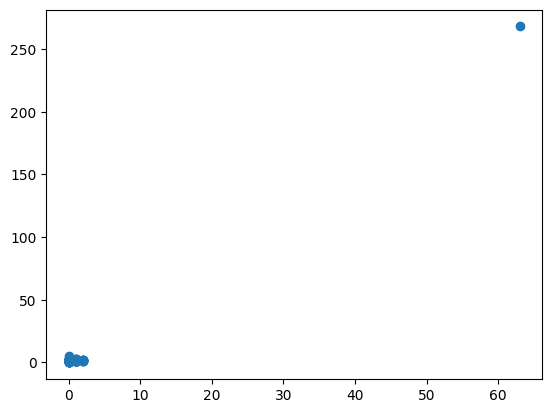

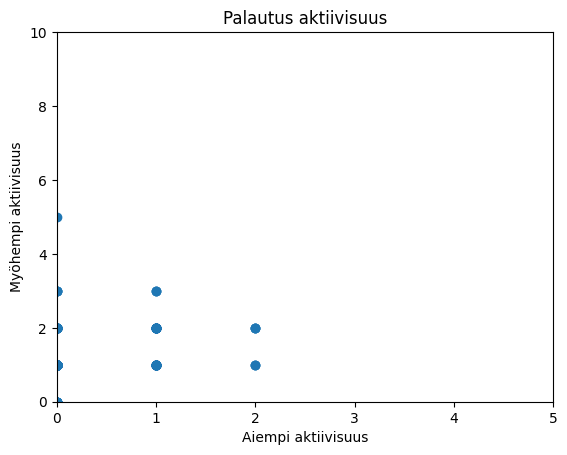

268.0 0.0
63.0 0.0


In [7]:
import matplotlib.pyplot as plt
activity = logs1[logs1["Kuvaus"].isin(["Tenttivastaus palautettu", "Palautus on lähetetty"])]
neljannes = ((activity["Aika"].max()-activity["Aika"].min()))/4
early = activity[activity["Aika"]-activity["Aika"].min() <= neljannes]
later = activity[activity["Aika"]-activity["Aika"].min() > neljannes]
earlyavgs = np.empty(shape=0)
lateravgs = np.empty(shape=0)
for i in ids:
    sr = "The user with id '"+i
    earlyactivity = len(early[early["Alkuperä"].str.startswith(sr) == True].index) + len(early[early["Unnamed: 6"].str.startswith(sr) == True].index)
    lateractivity = len(later[later["Alkuperä"].str.startswith(sr) == True].index) + len(later[later["Unnamed: 6"].str.startswith(sr) == True].index)
    earlyavgs = np.append(earlyavgs, earlyactivity)
    lateravgs = np.append(lateravgs, lateractivity)
plt.scatter(earlyavgs, lateravgs)
plt.show()
plt.title("Palautus aktiivisuus")
plt.xlim(0, 5)
plt.xlabel("Aiempi aktiivisuus")
plt.ylim(0, 10)
plt.ylabel("Myöhempi aktiivisuus")
plt.scatter(earlyavgs, lateravgs)
plt.show()
print(lateravgs.max(), lateravgs.min())
print(earlyavgs.max(), earlyavgs.min())

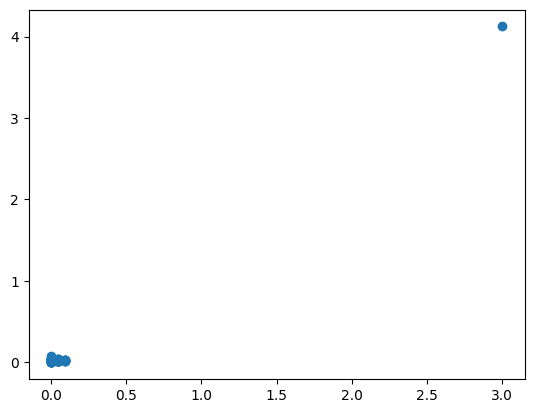

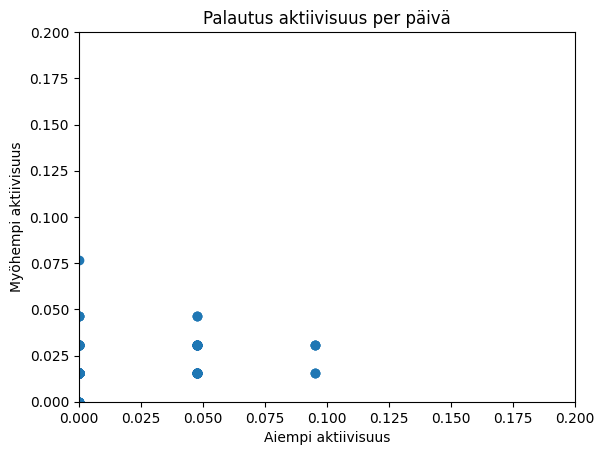

4.123076923076923 0.0
3.0 0.0


In [8]:
activity = logs1[logs1["Kuvaus"].isin(["Tenttivastaus palautettu", "Palautus on lähetetty"])]
neljannes = ((activity["Aika"].max()-activity["Aika"].min()))/4
early = activity[activity["Aika"]-activity["Aika"].min() <= neljannes]
later = activity[activity["Aika"]-activity["Aika"].min() > neljannes]
earlyavgs = np.empty(shape=0)
lateravgs = np.empty(shape=0)
for i in ids:
    sr = "The user with id '"+i
    earlyactivity = len(early[early["Alkuperä"].str.startswith(sr) == True].index) + len(early[early["Unnamed: 6"].str.startswith(sr) == True].index)
    lateractivity = len(later[later["Alkuperä"].str.startswith(sr) == True].index) + len(later[later["Unnamed: 6"].str.startswith(sr) == True].index)
    earlyavgs = np.append(earlyavgs, earlyactivity/neljannes.days)
    lateravgs = np.append(lateravgs, lateractivity/(((activity["Aika"].max()-activity["Aika"].min())).days-neljannes.days))
plt.scatter(earlyavgs, lateravgs)
plt.show()
plt.title("Palautus aktiivisuus per päivä")
plt.xlim(0, 0.2)
plt.xlabel("Aiempi aktiivisuus")
plt.ylim(0, 0.2)
plt.ylabel("Myöhempi aktiivisuus")
plt.scatter(earlyavgs, lateravgs)
plt.show()
print(lateravgs.max(), lateravgs.min())
print(earlyavgs.max(), earlyavgs.min())

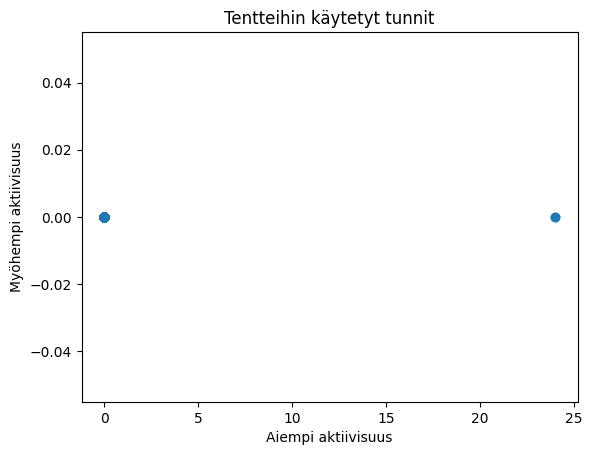

0.0 0.0
24.0 0.0


In [9]:
activity = logs1[logs1["Kuvaus"].isin(["Tenttivastaus palautettu", "Tenttiin vastaaminen aloitettu"])]
neljannes = ((activity["Aika"].max()-activity["Aika"].min()))/4
early = activity[activity["Aika"]-activity["Aika"].min() <= neljannes]
later = activity[activity["Aika"]-activity["Aika"].min() > neljannes]
earlyavgs = np.empty(shape=0)
lateravgs = np.empty(shape=0)
for i in ids:
    sr = "The user with id '"+i
    earlyactivity = pd.concat([early[early["Alkuperä"].str.startswith(sr) == True], early[early["Unnamed: 6"].str.startswith(sr) == True]])
    lateractivity = pd.concat([later[later["Alkuperä"].str.startswith(sr) == True], later[later["Unnamed: 6"].str.startswith(sr) == True]])
    earlyactivity = earlyactivity.sort_values(by="Aika").to_numpy()
    lateractivity = lateractivity.sort_values(by="Aika").to_numpy()
#    if len(earlyactivity) > 0:
#        print(earlyactivity[0])
#    if len(lateractivity) > 0:
#        print(lateractivity[0])
    total_time = 0
    counter = 0
    start_time = None
    if len(earlyactivity) > 0:
        for l in earlyactivity:
            if l[4] == "Tenttiin vastaaminen aloitettu":#Kuvaus
                if counter == 0:
                    start_time = l[0]
                counter += 1
            else:
                counter -= 1
                if counter == 0:
                    total_time += (l[0]-start_time).total_seconds()/3600
                    start_time = None
    earlyavgs = np.append(earlyavgs, total_time)
    total_time = 0
    if len(lateractivity) > 0:
        for l in lateractivity:
            if l[4] == "Tenttiin vastaaminen aloitettu":#Kuvaus
                if counter == 0:
                    start_time = l[0]
                counter += 1
            else:
                counter -= 1
                if counter == 0:
                    total_time += (l[0]-start_time).total_seconds()/3600
                    start_time = None
    lateravgs = np.append(lateravgs, total_time)
plt.title("Tentteihin käytetyt tunnit")
plt.xlabel("Aiempi aktiivisuus")
plt.ylabel("Myöhempi aktiivisuus")
plt.scatter(earlyavgs, lateravgs)
plt.show()
print(lateravgs.max(), lateravgs.min())
print(earlyavgs.max(), earlyavgs.min())